# --------------------------------------------------------------
# Code for Quadruple tank example: Standard DeepONet architecture
# --------------------------------------------------------------
## This notebook includes:
 - Input signal generation (multisine)
 - Simulation of 4tank Dynamics and data generation 
 - DeepONet prediction model learning using pytorch
 - Model Predictive Control (MPC) simulation using CasADi
# --------------------------------------------------------------

### Import required packages 

In [ ]:
# Standard libraries
import time
import itertools

# Scientific computing
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.io import savemat

# Plotting
import matplotlib.pyplot as plt

# Deep learning
import torch
import torch.nn.functional as F
import models  # your custom model module

# Optimization (solving the MPC problem)
import casadi as ca

# Functions used in scripts
from functions import four_tank, NN, multisine


### Generate input signal used for model learning 

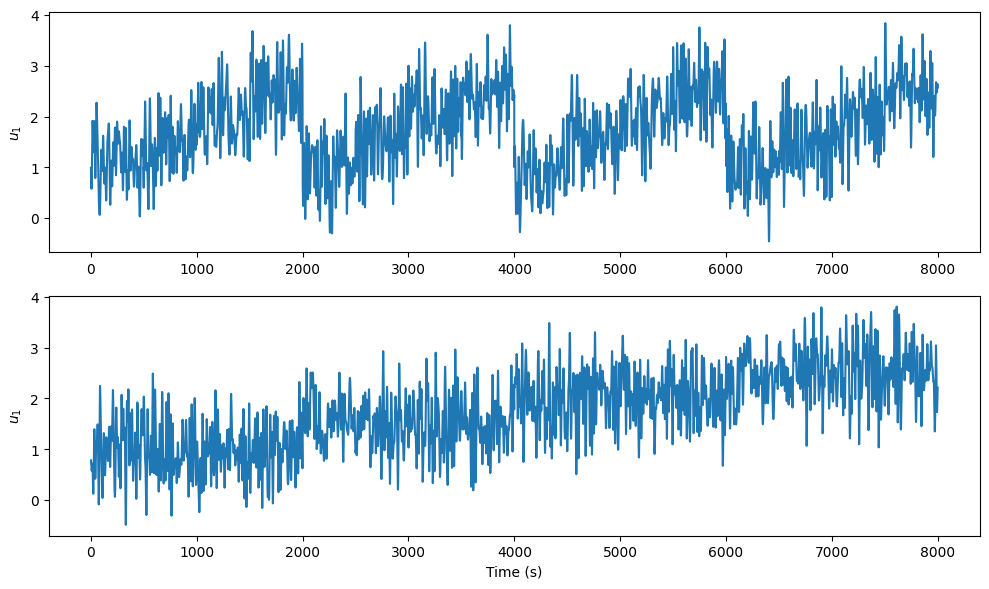

In [4]:
# Generate piecewise constanrt reference for u1
u1_data1 =  np.tile([1.000], (500, 1))
u1_data2 =  np.tile([1.500], (500, 1))
u1_data3 =  np.tile([2.000], (500, 1))
u1_data4 =  np.tile([2.500], (500, 1))

u1_data_all = np.concatenate((u1_data1, u1_data2, u1_data3, u1_data4), axis=0)
u1_data_all = np.concatenate((u1_data_all, u1_data_all, u1_data_all, u1_data_all), axis=0)

# Generate piecewise constanrt reference for u2
u2_data1 =  np.tile([1.000], (2000, 1))
u2_data2 =  np.tile([1.500], (2000, 1))
u2_data3 =  np.tile([2.000], (2000, 1))
u2_data4 =  np.tile([2.500], (2000, 1))
u2_data_all = np.concatenate((u2_data1, u2_data2, u2_data3, u2_data4), axis=0)

# Add multisine to piecewise constant signals
u_data_1_additional = 0.5*multisine(N_points_per_period=8000, N_periods=1, pmin=1, pmax=500, n_crest_factor_optim=100,seed=42)
u_data_2_additional = 0.5*multisine(N_points_per_period=8000, N_periods=1, pmin=1, pmax=500, n_crest_factor_optim=100,seed=36)
u1_data = u1_data_all + u_data_1_additional.reshape(-1, 1)
u2_data = u2_data_all + u_data_2_additional.reshape(-1, 1)
u_data = np.hstack((u1_data,u2_data))

# Plot the final input signal which will be used to generate the data
plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(u1_data)
plt.ylabel('$u_1$')
plt.subplot(2, 1, 2)
plt.plot(u2_data)
plt.ylabel('$u_1$')
plt.xlabel('Time (s)')
plt.tight_layout()
plt.show()

### Generate output data for the van der Quadruple tank example, used for training

C:\Users\20183249\AppData\Local\Temp\ipykernel_16700\1277242690.py:15: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  u1 = float(u1_data[i])
C:\Users\20183249\AppData\Local\Temp\ipykernel_16700\1277242690.py:16: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  u2 = float(u2_data[i])


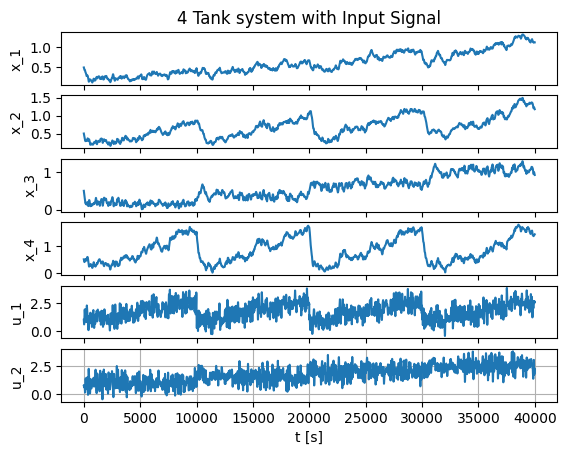

In [5]:
# Model parameters
N = 20 # prediction horizon of the controller
Ts = 5 # Sampling time of the controller
a1, a2, a3, a4 = 1.31e-4, 1.51e-4, 9.27e-5, 8.82e-5
gamma_a, gamma_b = 0.3, 0.4
g, Sc = 9.81, 0.06
params = {'a1': a1, 'a2': a2, 'a3': a3, 'a4': a4, 'gamma_a': gamma_a, 'gamma_b': gamma_b, 'g': g, 'Sc': Sc}

x0 = np.array([0.5, 0.5, 0.5, 0.5])  # Initial conditions: [h1, h2, h3, h4]
t_vec = [0]
x = [x0]

# Main loop
for i in range(len(u1_data)):
    u1 = float(u1_data[i])
    u2 = float(u2_data[i])
    sol = solve_ivp(lambda t, y: four_tank(t, y, u1, u2, params),[0, Ts], x0, method='RK45')
    x0 = sol.y[:, -1]
    x.append(x0)  # store state
    t_vec.append((i+1) * Ts)  # store time

# Convert list to numpy array 
x = np.array(x)
t_vec = np.array(t_vec)


# Plotting
plt.subplot(6,1,1)
plt.plot(t_vec, x[:, 0], label='x_1')
plt.title('4 Tank system with Input Signal')
plt.ylabel('x_1')
plt.subplot(6,1,2)
plt.plot(t_vec, x[:, 1], label='x_2')
plt.ylabel('x_2')
plt.subplot(6,1,3)
plt.plot(t_vec, x[:, 2], label='x_3')
plt.ylabel('x_3')
plt.subplot(6,1,4)
plt.plot(t_vec, x[:, 3], label='x_4')
plt.ylabel('x_4')
plt.subplot(6,1,5)
plt.plot(t_vec[0:len(u1_data)], u1_data, label='u_1')
plt.ylabel('u_1')
plt.subplot(6,1,6)
plt.plot(t_vec[0:len(u2_data)], u2_data, label='u_2')
plt.ylabel('u_2')
plt.xlabel('t [s]')
plt.grid()
plt.show()

### Generate datatrices used for model learning

In [6]:
# Initialze empty data matrices
Z = [] # Initial condition + time z = [x0,t] data matrix
Y = [] # Output data matrix
U = [] # Input data matrix

# For loop for generating Hankel matrices
for i in range(len(x[:,0])-N):
    for j in range(N):
        if j == 0:
            Y_i = x[i + j+1,:]
            Z_i = np.hstack((x[i,:],(j+1)*Ts))
            U1_i = u_data[i:i+N,0]
            U2_i = u_data[i:i+N,1]
        else:
            Y_i = np.vstack((Y_i,x[i + j+1,:])) 
            Z_i = np.vstack((Z_i,np.hstack((x[i,:],(j+1)*Ts))))
            U1_i = np.vstack((U1_i,u_data[i:i+N,0])) 
            U2_i = np.vstack((U2_i,u_data[i:i+N,1])) 

    if i == 0:
        Y = Y_i
        Z = Z_i
        U1 = U1_i
        U2 = U2_i
    else:
        Y = np.vstack((Y,Y_i))
        Z = np.vstack((Z,Z_i))
        U1 = np.vstack((U1,U1_i))
        U2 = np.vstack((U2,U2_i))

# Divide data into training and validation (7500*N samples for training)
U1_train = U1[0:150000,:]
U1_test = U1[150000:,:]
U2_train = U2[0:150000,:]
U2_test = U2[150000:,:]
Z_train = Z[0:150000,:]
Z_test = Z[150000:,:]
Y_train = Y[0:150000,:]
Y_test = Y[150000:,:]

# Optional: print shapes
print("Shapes after split:")
print(f"U1_train: {U1_train.shape}, U1_test: {U1_test.shape}")
print(f"U2_train: {U2_train.shape}, U2_test: {U2_test.shape}")
print(f"X0_train: {Z_train.shape}, X0_test: {Z_test.shape}")
print(f"Y_train: {Y_train.shape}, Y_test: {Y_test.shape}")

Shapes after split:
U1_train: (150000, 20), U1_test: (9620, 20)
U2_train: (150000, 20), U2_test: (9620, 20)
X0_train: (150000, 5), X0_test: (9620, 5)
Y_train: (150000, 4), Y_test: (9620, 4)


### Train the standard DeepONet model 

In [ ]:
# Define the network dimensions
ld_list = [20] # Neurons in output layer, change to [20,30,...] to train for multiple combinations
neuron_list = [20] # Neurons per hidden layer, change to [20,30,...] to train for multiple combinations
layer_list = [1] # number of hidden layers, change to [2,3,...] to train for multiple combinations
N_epoch = 40000 # Number of epochs used for training the model
N_comb = len(ld_list)*len(neuron_list)*len(layer_list) # Total number of hyperparameter configurations to train for

# make sure that GPU is used when available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Convert training data to tensors
trunk_input_train = torch.tensor(Z_train, dtype=torch.float32).to(device)
branch1_input_train = torch.tensor(U1_train, dtype=torch.float32).to(device)
branch2_input_train = torch.tensor(U2_train, dtype=torch.float32).to(device)
output_train = torch.squeeze(torch.tensor(Y_train, dtype=torch.float32).to(device))

# Convert validation data to tensors
trunk_input_val = torch.tensor(Z_test, dtype=torch.float32).to(device)
branch1_input_val = torch.tensor(U1_test, dtype=torch.float32).to(device)
branch2_input_val = torch.tensor(U2_test, dtype=torch.float32).to(device)
output_val = torch.squeeze(torch.tensor(Y_test, dtype=torch.float32).to(device))

# Network and data dimensions
B_train = len(trunk_input_train[:,0]) # Batch size for training data
B_val = len(trunk_input_val[:,0]) # Batch size for validation data
nx = 4 # number of states 4tank system
ny = 4 # number of outputs 4tank system
nu = 2 # number of inputs 4tank system

# Define the network using pytorch 
def train(idx,neuron,layer,ld,loss_val_i, niter):
    # Define the Branch 1 network: (for input 1)
    branch1 = models.MLP(
        layers=[N] + [neuron] * layer + [ld*ny],
        activation=F.tanh,
    ).to(device)

    # Define the Branch 2 network: (for input 2)
    branch2 = models.MLP(
        layers=[N] + [neuron] * layer + [ld*ny],
        activation=F.tanh,
    ).to(device)

    # Define the Trunk network:
    trunk = models.MLP(layers=[nx+1] + [neuron] * layer + [ld], activation=F.tanh).to(device)

    # Define the optimizer, learning rate, weight decay
    optimizer = torch.optim.AdamW(
        list(branch1.parameters()) + list(branch2.parameters()) + list(trunk.parameters()), 
        lr=1e-3,
        weight_decay=1e-4  # L2 regularization (weight decay)
    )

    # Add a learning rate scheduler that reduces the learning rate by a factor of gamma every step_size iterations
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10000, gamma=0.1)

    # Initialize empty list for storing the training and validation loss
    train_loss_hist = []
    val_loss_hist = []
    t0 = time.time()
    # training loop
    for i in range(niter):
        # Training step
        def train_step():
            optimizer.zero_grad() # reset the gradients    
            # Forward pass:               
            b1_out = branch1(branch1_input_train) # Branch1 net forward pass
            b2_out = branch2(branch2_input_train) # Branch1 net forward pass
            b_out = b1_out*b2_out # Branch product forward pass
            t_out = trunk(trunk_input_train) # Trunk net forward pass
            b_out = b_out.reshape(B_train, ny, ld) # convert branch output to matrix
            u_pred = torch.einsum("bij,bj->bi", b_out, t_out) # Product layer
            loss = torch.mean((u_pred - output_train) ** 2) / torch.mean((output_train) ** 2) # Calculate training loss 
            # Backward pass
            loss.backward() 
            # Update parameters
            optimizer.step() 
            return loss
        
        # Validation step
        def validation_step():
             with torch.no_grad():               
                b1_out = branch1(branch1_input_val)
                b2_out = branch2(branch2_input_val)
                b_out = b1_out*b2_out
                t_out = trunk(trunk_input_val)
                b_out = b_out.reshape(B_val, ny, ld)
                u_pred = torch.einsum("bij,bj->bi", b_out, t_out)
                loss = torch.mean((u_pred - output_val) ** 2) / torch.mean((output_val) ** 2)
                return loss

        loss_train = train_step() # Perform a training step (includes forward pass, loss calc, backward pass, optimizer step)
        loss_val = validation_step() # Perform a validation step (forward pass + loss calc, no weight updates)
        l_train = loss_train.detach().cpu().numpy() # Move training loss tensor to CPU, detach from graph, convert to NumPy
        l_val = loss_val.detach().cpu().numpy() # Same as above for validation loss


        train_loss_hist.append(l_train) # Append training loss data 
        val_loss_hist.append(l_val) # Append validation loss data 

        current_lr = optimizer.param_groups[0]['lr'] # Get the current learning rate from the optimizer
        current_lr = round(current_lr, 5) # Round the learning rate to 5 decimal places for printing
        
        # Print usefull information during training:
        if i % 10 == 0:
            print(
                "index: ",
                idx,
                "/ ",
                N_comb,
                "Epoch: ",
                i + 1,
                "Learning rate: ",
                current_lr,
                "Train loss",
                l_train,
                "Val loss",
                l_val,
                flush=True,
            )
        # Save the model every 100 iterations and only when validation loss has decreased
        if i % 100 == 0 and loss_val_i >= l_val:
            loss_val_i = l_val
            l_indx_i = i
            torch.save(branch1, "data_standard/kan_mlp_branch1_idx_{}".format(str(int(idx))))
            torch.save(branch2, "data_standard/kan_mlp_branch2_idx_{}".format(str(int(idx))))
            torch.save(trunk, "data_standard/kan_mlp_trunk_idx_{}".format(str(int(idx))))

        # Step the scheduler at the end of each iteration
        scheduler.step()
        
    t1 = time.time()
    print("Total time: ", t1 - t0, flush=True)
    t_elapsed = t1 - t0
    
    # Save training and validation losses
    np.save("data_standard/train_loss.npy", train_loss_hist, allow_pickle=True)
    np.save("data_standard/val_loss.npy", val_loss_hist, allow_pickle=True)

    return np.array(train_loss_hist), np.array(val_loss_hist), l_indx_i, loss_val_i, t_elapsed


# start of the ablation study 
ablation_results = [] # Initialize empty list for storing the ablation results 
combinations = itertools.product(ld_list,neuron_list,layer_list) # Generate set of hyperparameter configurations for ablation study 
idx_i = 0 # Initialize training index 

# Looping through the range of indices (1 to idx_total-1 in this case, but you can extend it)
for ld_i, neuron_i, layer_i in combinations:
    idx_i += 1
    # Call the train function with the current index
    train_loss_hist_i, val_loss_hist_i, l_indx_opt, loss_val_opt, t_elapsed   = train(idx=idx_i,ld=ld_i,neuron=neuron_i,layer=layer_i,loss_val_i=float('inf'),niter=N_epoch)
    
    # Create a dictionary to store the results
    results = {
        'idx': idx_i,
        'neurons output layer': ld_i,
        'neurons hidden per layer': neuron_i,
        'hidden layers': layer_i,
        'training loss': train_loss_hist_i,
        'validation loss': val_loss_hist_i,
        'training time': t_elapsed
    }
    
    # Append the results to the ablation_results list
    ablation_results.append(results)


Using device: cpu
index:  1 /  1 Epoch:  1 Learning rate:  0.001 Train loss 1.6398001 Val loss 1.2092484
index:  1 /  1 Epoch:  11 Learning rate:  0.001 Train loss 0.18564922 Val loss 0.037645496
index:  1 /  1 Epoch:  21 Learning rate:  0.001 Train loss 0.14629357 Val loss 0.102770135
index:  1 /  1 Epoch:  31 Learning rate:  0.001 Train loss 0.13177389 Val loss 0.0985554
index:  1 /  1 Epoch:  41 Learning rate:  0.001 Train loss 0.10606006 Val loss 0.057410326
index:  1 /  1 Epoch:  51 Learning rate:  0.001 Train loss 0.08872941 Val loss 0.06729838
index:  1 /  1 Epoch:  61 Learning rate:  0.001 Train loss 0.07629953 Val loss 0.049891744
index:  1 /  1 Epoch:  71 Learning rate:  0.001 Train loss 0.06667963 Val loss 0.042295404
index:  1 /  1 Epoch:  81 Learning rate:  0.001 Train loss 0.05848945 Val loss 0.036416408
index:  1 /  1 Epoch:  91 Learning rate:  0.001 Train loss 0.051213026 Val loss 0.031000523
index:  1 /  1 Epoch:  101 Learning rate:  0.001 Train loss 0.045047976 Val lo

### Convert the ablation results to a .mat file for analysis with MATLAB

Text(0.5, 1.0, 'Training and validation loss')

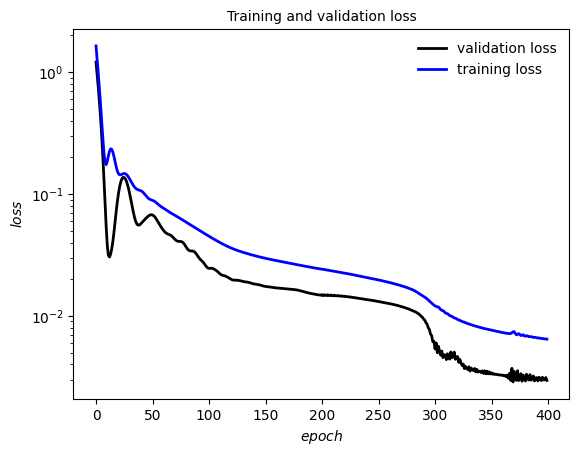

In [8]:
# Prepare dictionary for saving in .mat format
ablation_mat = {}

# Flatten the ablation_results list into a structured dict
for i, result in enumerate(ablation_results):
    ablation_mat[f'result_{i}'] = {
        'idx': result['idx'],
        'neurons_output_layer': result['neurons output layer'],
        'neurons_hidden_per_layer': result['neurons hidden per layer'],
        'hidden_layers': result['hidden layers'],
        'train_loss': np.array(result['training loss']),
        'val_loss': np.array(result['validation loss']),
        'T_train': np.array(result['training time'])
    }

# Save the structured dict to a .mat file
savemat("data_standard/ablation_results.mat", ablation_mat)

# Make figure
val_loss = np.load("data_standard/val_loss.npy")
train_loss = np.load("data_standard/train_loss.npy")
plt.semilogy(val_loss, '-k', lw=2.0, label="validation loss")
plt.semilogy(train_loss, '-b', lw=2.0, label="training loss")
plt.xlabel('$epoch$')
plt.ylabel('$loss$')
plt.legend(frameon=False, loc = 'best')
plt.title('Training and validation loss', fontsize = 10)

### Perform standard DeepONet based MPC simulation

i = 0 / 780

******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

i = 1 / 780
i = 2 / 780
i = 3 / 780
i = 4 / 780
i = 5 / 780
i = 6 / 780
i = 7 / 780
i = 8 / 780
i = 9 / 780
i = 10 / 780
i = 11 / 780
i = 12 / 780
i = 13 / 780
i = 14 / 780
i = 15 / 780
i = 16 / 780
i = 17 / 780
i = 18 / 780
i = 19 / 780
i = 20 / 780
i = 21 / 780
i = 22 / 780
i = 23 / 780
i = 24 / 780
i = 25 / 780
i = 26 / 780
i = 27 / 780
i = 28 / 780
i = 29 / 780
i = 30 / 780
i = 31 / 780
i = 32 / 780
i = 33 / 780
i = 34 / 780
i = 35 / 780
i = 36 / 780
i = 37 / 780
i = 38 / 780
i = 39 / 780
i = 40 / 780
i = 41 / 780
i = 42 / 780
i = 43 / 780
i = 44 / 780
i = 45 / 780
i = 46 / 780
i = 47 / 780

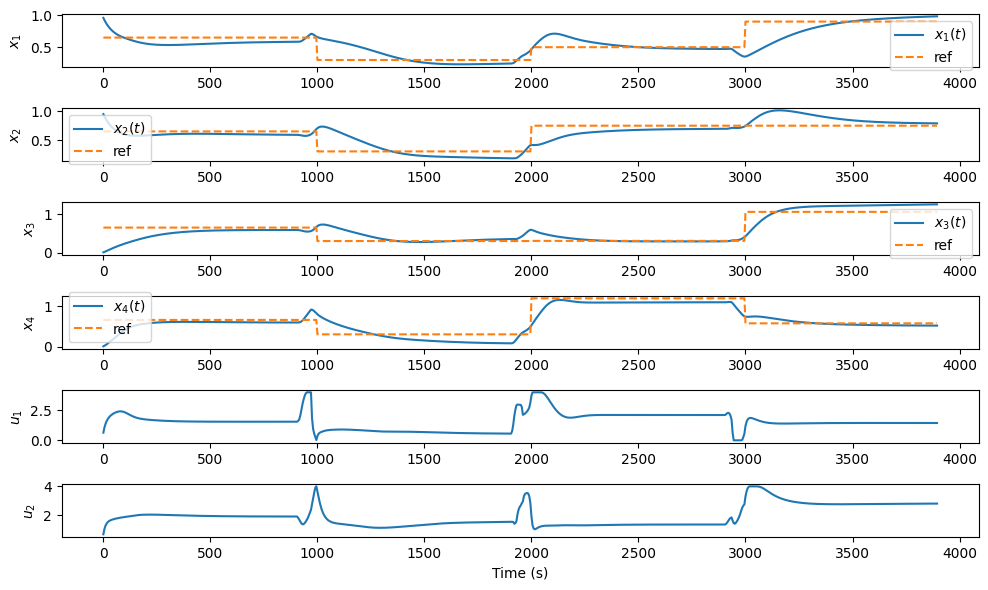

In [9]:
# select optimal index based on the minimal validation loss in ablation_results:
idx_opt = 1  # change to correct index as defined in the code block: Train the standard DeepONet model 
branch1 = torch.load("data_standard/kan_mlp_branch1_idx_{}".format(str(int(idx_opt))), map_location=torch.device('cpu'), weights_only=False)
branch2 = torch.load("data_standard/kan_mlp_branch2_idx_{}".format(str(int(idx_opt))), map_location=torch.device('cpu'), weights_only=False)
trunk = torch.load("data_standard/kan_mlp_trunk_idx_{}".format(str(int(idx_opt))), map_location=torch.device('cpu'), weights_only=False)

# MPC parameters
ld = 20 # Select here correct number of neurons in output layer of model with index idx_opt
N = 20  # Select here correct prediction horizon of model with index idx_opt

# System dimensions van der
nx = 4  # [h1, h2, h3, h4]
ny = 4  # [h1, h2, h3, h4]
nu = 2  # [u1 , u2]

# MPC cost function matrices
Q = np.eye(N*ny) * 100
R = np.eye(N)


# Define constant pieces for reference signal
ref1 = np.tile([0.650, 0.650, 0.652, 0.664], (200, 1))
ref2 = np.tile([0.300, 0.300, 0.301, 0.306], (200, 1))
ref3 = np.tile([0.500, 0.750, 0.305, 1.200], (200, 1))
ref4 = np.tile([0.900, 0.750, 1.062, 0.579], (200, 1))

# Concatenate them along the first axis (time steps)
xref_traj = np.concatenate((ref1, ref2, ref3, ref4), axis=0)  

# Set up optimization problem
opti = ca.Opti()
y = opti.variable(ny*N,)
u1 = opti.variable(N,)
u2 = opti.variable(N,)
du1 = opti.variable(N,)
du2 = opti.variable(N,)
x0 = opti.parameter(nx)
z = opti.parameter(nx+1)
u0 = opti.parameter(nu)
ref = opti.parameter(ny*N,)

# Define cost function
cost = ca.mtimes([(y-ref).T, Q, (y-ref)]) + ca.mtimes([du1.T, R, du1])  + ca.mtimes([du2.T, R, du2])

# Neural network predictions
b1_out = NN(u1, branch1, np.tanh)
b2_out = NN(u2, branch2, np.tanh)
b_out = ca.reshape((b1_out*b2_out), ld, ny)

# loop over t = 1T_s, 2T_s, ..., NT_s
for i in range(N):
    z = ca.vertcat(x0, (i+1)*Ts)  # Concatenate x(0) with t = (i+1)Ts
    t_out = NN(z, trunk, np.tanh) # output trunk network
    opti.subject_to(y[i*ny:(i+1)*ny] == b_out.T@t_out)  # Prediction model 

# Define constrains for the MPC problem
opti.subject_to(du1[0] == u1[0] - u0[0])
opti.subject_to(du1[1:] == u1[1:] - u1[:-1])
opti.subject_to(du2[0] == u2[0] - u0[1])
opti.subject_to(du2[1:] == u2[1:] - u2[:-1])
opti.subject_to(opti.bounded(0, u1, 4.0))     # input bounds
opti.subject_to(opti.bounded(0, u2, 4.0))     # input bounds

# Define optimization problem
opti.minimize(cost)

# Solver options
opti.solver('ipopt', {
    'ipopt.print_level': 0,
    'print_time': 0
    })

x_vals = [] # Initialize empty list for storing state data
u1_vals = [] # Initialize empty list for storing input data
u2_vals = [] # Initialize empty list for storing input data
solve_times = []  # Initialize empty list to store time per control action 

x_current = np.array([1, 1, 0, 0])  # Initial conditions 
u1_mpc = np.array([0]) # Initial condition for inut (needed for \delta u1(0) = u1(0) - u1(-1))
u2_mpc = np.array([0]) # Initial condition for inut (needed for \delta u2(0) = u2(0) - u2(-1))

# Warm start for input sequence at k=0
previous_u1_guess = np.zeros(N)
previous_u2_guess = np.zeros(N)
previous_du1_guess = np.zeros(N)
previous_du2_guess = np.zeros(N)

# Start of the simulation loop
for i in range(len(xref_traj)-N):
    print(f'i = {i} / {len(xref_traj)-N}')
    REF = xref_traj[i,:]
    for j in range(N-1):
        REF = np.hstack((REF,xref_traj[i+j,:]))

    opti.set_value(x0, x_current)
    opti.set_value(u0[0], u1_mpc)
    opti.set_value(u0[1], u2_mpc)
    opti.set_value(ref, REF)

    # Initial guess for the solver
    opti.set_initial(u1, previous_u1_guess)
    opti.set_initial(u2, previous_u2_guess)
    opti.set_initial(du1, previous_du1_guess)
    opti.set_initial(du2, previous_du2_guess)

    start = time.perf_counter()
    sol = opti.solve()
    elapsed = time.perf_counter() - start

    previous_u1_guess = sol.value(u1)
    previous_u1_guess = np.concatenate([previous_u1_guess[1:], previous_u1_guess[-1:]])
    previous_u2_guess = sol.value(u2)
    previous_u2_guess = np.concatenate([previous_u2_guess[1:], previous_u2_guess[-1:]])
    previous_du1_guess = sol.value(du1)
    previous_du1_guess = np.concatenate([previous_du1_guess[1:], previous_du1_guess[-1:]])
    previous_du2_guess = sol.value(du2)
    previous_du2_guess = np.concatenate([previous_du2_guess[1:], previous_du2_guess[-1:]])

    solve_times.append(elapsed)  # Store each solve time

    u1_mpc = sol.value(u1[0])
    u2_mpc = sol.value(u2[0])
    
    sol = solve_ivp(lambda t, x: four_tank(t, x, u1_mpc, u2_mpc, params), [0, Ts], x_current)

    # Take the last value as the new initial condition
    x_next = sol.y[:, -1] # measured state at t = (i+1)T_s
    x_vals.append(x_next) # Append state data vector
    u1_vals.append(u1_mpc) # Append input 1 data vector
    u2_vals.append(u2_mpc) # Append input 1 data vector
    x_current = x_next # Initialize new current state for next iteration

solve_times = np.array(solve_times) # Convert control times to numpy array 
x_vals = np.array(x_vals) # Convert state data to numpy array 
u1_vals = np.array(u1_vals) # Convert input data to numpy array 
u2_vals = np.array(u2_vals) # Convert input data to numpy array 

t_vec = np.arange(len(xref_traj)-N) * Ts # Define time vector

# Make figure of the closed--loop response
plt.figure(figsize=(10, 6))
for i in range(4):
    plt.subplot(6, 1, i+1)
    plt.plot(t_vec, x_vals[:, i], label=f'$x_{i+1}(t)$')
    plt.plot(t_vec, xref_traj[:len(x_vals), i], '--', label='ref')
    plt.ylabel(f'$x_{i+1}$')
    plt.legend()
plt.subplot(6, 1, 5)
plt.plot(t_vec, u1_vals)
plt.ylabel('$u_1$')
plt.subplot(6, 1, 6)
plt.plot(t_vec, u2_vals)
plt.ylabel('$u_2$')
plt.xlabel('Time (s)')
plt.tight_layout()
plt.show()




## save MPC results a .mat files for analysis in Matlab

In [10]:
# Put them in a dictionary with variable names
data_to_save = {
    "x_vals_st": x_vals,
    "u1_vals_st": u1_vals,
    "u2_vals_st": u2_vals,
    "solve_times_st": solve_times,
    "xref_traj_st": xref_traj    
}

# Save to a .mat file
savemat('data_standard/standard_4tank.mat', data_to_save)
print("Arrays saved to 'standard_4tank.mat'")



Arrays saved to 'standard_4tank.mat'
